## 1.Dataset

In [1]:

from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Connect Google Drive
drive.mount("/content/drive")

# Project directory
PROJECT_DIR = Path("/content/drive/MyDrive/industrial-data-operations")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

# Load cleaned datasets
machines = pd.read_csv(PROCESSED_DIR / "PdM_machines_processed.csv")
telemetry = pd.read_csv(PROCESSED_DIR / "PdM_telemetry_processed.csv")
errors = pd.read_csv(PROCESSED_DIR / "PdM_errors_processed.csv")
maintenance = pd.read_csv(PROCESSED_DIR / "PdM_maint_processed.csv")
failures = pd.read_csv(PROCESSED_DIR / "PdM_failures_processed.csv")

# Convert datetime columns
for df in [telemetry, errors, maintenance, failures]:
    df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")

print("All datasets loaded successfully!")
print("Machines:", machines.shape)
print("Telemetry:", telemetry.shape)
print("Errors:", errors.shape)
print("Maintenance:", maintenance.shape)
print("Failures:", failures.shape)


Mounted at /content/drive
All datasets loaded successfully!
Machines: (100, 3)
Telemetry: (876100, 6)
Errors: (3919, 3)
Maintenance: (3286, 3)
Failures: (761, 3)


##2.Analisis kondisi sensor (EDA)

mengetahui nilai rata-rata, standar deviasi, nilai minimum, dan maksimum setiap sensor sebelum membuat fitur baru

In [2]:

# Sensor columns
sensor_cols = ["volt", "rotate", "pressure", "vibration"]

# Check data types and missing values
print("=== TELEMETRY INFO ===")
print(telemetry.info())

print("\n=== MISSING VALUES ===")
print(telemetry[sensor_cols].isna().sum())

print("\n=== SENSOR STATISTICS ===")
display(telemetry[sensor_cols].describe().round(2))


=== TELEMETRY INFO ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 876100 entries, 0 to 876099
Data columns (total 6 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   datetime   876100 non-null  datetime64[ns]
 1   machineID  876100 non-null  int64         
 2   volt       876100 non-null  float64       
 3   rotate     876100 non-null  float64       
 4   pressure   876100 non-null  float64       
 5   vibration  876100 non-null  float64       
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 40.1 MB
None

=== MISSING VALUES ===
volt         0
rotate       0
pressure     0
vibration    0
dtype: int64

=== SENSOR STATISTICS ===


,volt,rotate,pressure,vibration
count,876100.00,876100.00,876100.00,876100.00
mean,170.78,446.61,100.86,40.39
std,15.51,52.67,11.05,5.37
min,97.33,138.43,51.24,14.88
25%,160.30,412.31,93.50,36.78
50%,170.61,447.56,100.43,40.24
75%,181.00,482.18,107.56,43.78
max,255.12,695.02,185.95,76.79


##3.Visualisasikan distribusi sensor

Grafik ini membantu kita melihat distribusi dan nilai sensor yang ekstrem. Jangan langsung menghapus outlier karena nilai ekstrem pada data industri bisa menunjukkan kondisi mesin yang perlu diselidiki

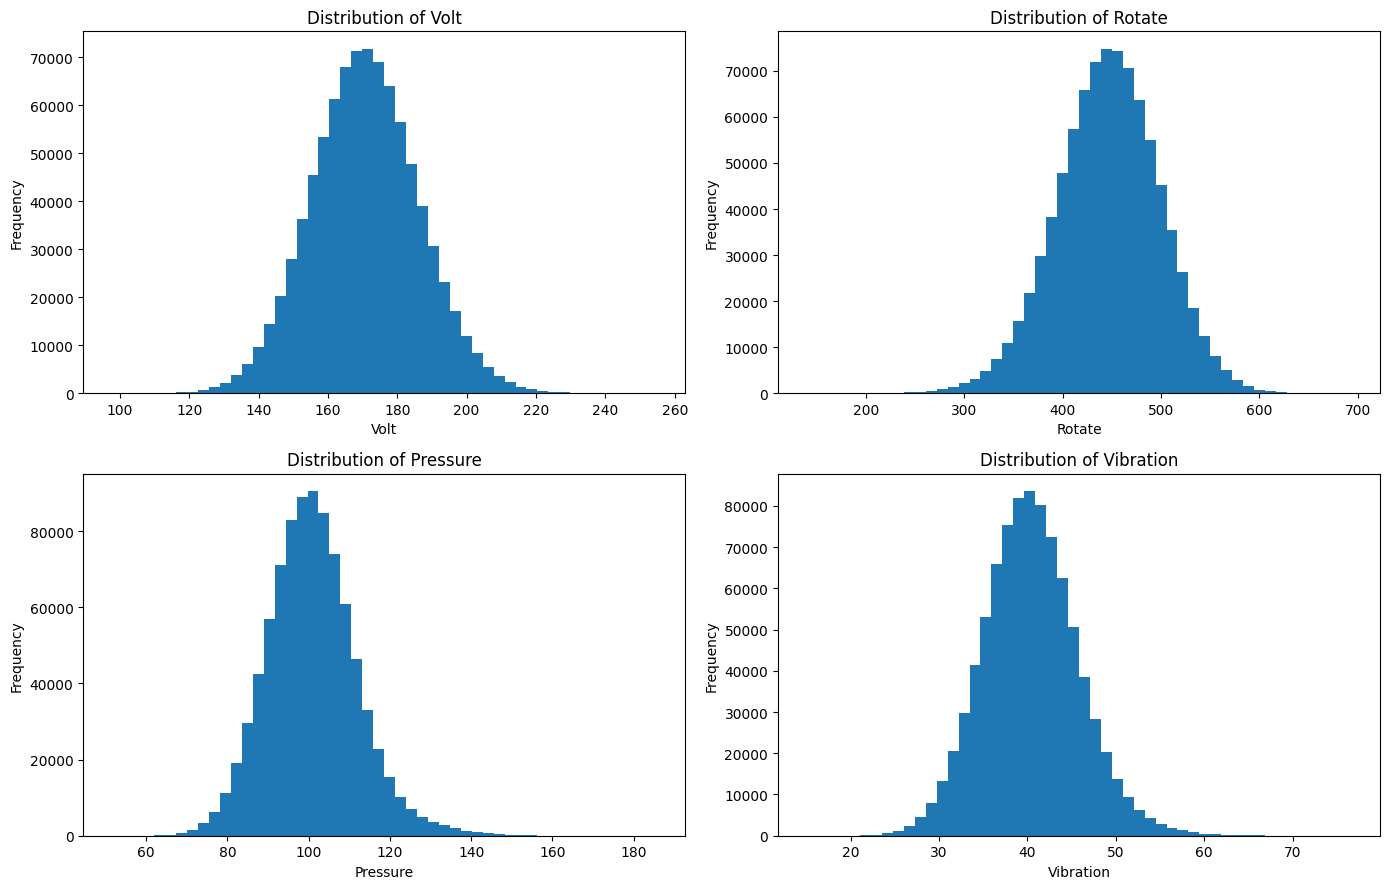

In [3]:

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, col in zip(axes.flatten(), sensor_cols):
    ax.hist(telemetry[col].dropna(), bins=50)
    ax.set_title(f"Distribution of {col.title()}")
    ax.set_xlabel(col.title())
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


##4.fitur baru untuk reliability analysis

menghitung rata-rata sensor per mesin dan jumlah event untuk setiap mesin

In [4]:

# Aggregate telemetry measurements per machine
sensor_features = (
    telemetry.groupby("machineID")
    .agg(
        avg_volt=("volt", "mean"),
        avg_rotate=("rotate", "mean"),
        avg_pressure=("pressure", "mean"),
        avg_vibration=("vibration", "mean"),
        max_vibration=("vibration", "max"),
        std_vibration=("vibration", "std"),
        telemetry_records=("machineID", "size")
    )
    .reset_index()
)

# Count recorded errors, failures, and maintenance events
error_counts = (
    errors.groupby("machineID")
    .size()
    .reset_index(name="total_errors")
)

failure_counts = (
    failures.groupby("machineID")
    .size()
    .reset_index(name="total_failures")
)

maintenance_counts = (
    maintenance.groupby("machineID")
    .size()
    .reset_index(name="total_maintenance_events")
)

# Combine features with machine information
reliability_features = (
    machines
    .merge(sensor_features, on="machineID", how="left")
    .merge(error_counts, on="machineID", how="left")
    .merge(failure_counts, on="machineID", how="left")
    .merge(maintenance_counts, on="machineID", how="left")
)

count_cols = [
    "total_errors",
    "total_failures",
    "total_maintenance_events"
]
reliability_features[count_cols] = (
    reliability_features[count_cols].fillna(0).astype(int)
)

display(reliability_features.head())
print("Number of machines:", len(reliability_features))
print("Number of columns:", len(reliability_features.columns))


,machineID,model,age,avg_volt,avg_rotate,avg_pressure,avg_vibration,max_vibration,std_vibration,telemetry_records,total_errors,total_failures,total_maintenance_events
0,1,model3,18,170.833898,446.336502,100.668306,40.586309,67.633435,5.542143,8761,35,7,37
1,2,model4,7,170.760482,446.388915,100.539930,40.301539,64.097877,5.313053,8761,28,4,32
2,3,model3,8,170.659235,446.583238,100.653114,40.475376,62.866344,5.248968,8761,39,5,37
3,4,model3,7,170.659728,446.053801,100.569902,40.341620,70.365920,5.299423,8761,31,6,33
4,5,model3,2,171.044435,446.858577,101.066188,40.264846,63.252497,5.296243,8761,38,7,35


Number of machines: 100
Number of columns: 13


Fitur baru yang dihasilkan antara lain avg_vibration, max_vibration, std_vibration, total_errors, dan total_failures. Ini membuat satu tabel analisis yang merangkum kondisi sensor dan riwayat event untuk setiap mesin

##Simpan hasil feature engineering

In [12]:

OUTPUT_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_file = OUTPUT_DIR / "machine_reliability_features.csv"
reliability_features.to_csv(output_file, index=False)

print("Feature engineering completed.")
print("Saved to:", output_file)


Feature engineering completed.
Saved to: /content/drive/MyDrive/industrial-data-operations/data/processed/machine_reliability_features.csv


##5.Top 10 mesin dengan failure terbanyak

mengidentifikasi mesin dengan jumlah failure tertinggi

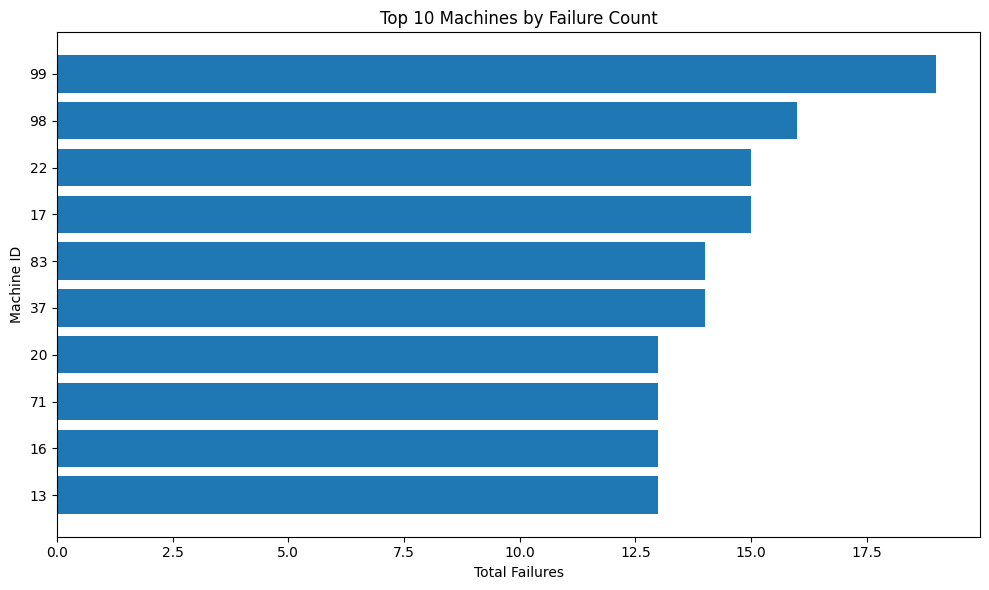

In [5]:

top_failures = (
    reliability_features
    .nlargest(10, "total_failures")
    .sort_values("total_failures")
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_failures["machineID"].astype(str),
    top_failures["total_failures"]
)
plt.title("Top 10 Machines by Failure Count")
plt.xlabel("Total Failures")
plt.ylabel("Machine ID")
plt.tight_layout()
plt.show()


### Top 10 Machines by Failure Count — Interpretation

**Objective:** Identify machines with the highest number of recorded failure events to support maintenance prioritization.

**Key Findings:**
- Machine 99 has the highest recorded failure count among the displayed machines, at approximately 19 events.
- Machine 98 follows with approximately 16 events.
- Machines 22 and 17 each recorded approximately 15 events.
- The remaining machines in the top 10 recorded approximately 13–14 events each.

**Operational Implications:**
Machine 99 should be prioritized for further investigation, followed by other machines with high failure counts. Maintenance teams could review historical failure records, component-level failure patterns, maintenance history, and sensor trends to identify potential areas for improvement.

**Limitations:**
Failure counts represent recorded events, not failure probability, downtime, or financial impact. A high count does not establish the cause of failure. Further investigation is required before making maintenance decisions.

##6.Distribusi failure berdasarkan model mesin

membandingkan model mesin

Grafik ini membantu membandingkan jumlah failure antar-model. Karena jumlah mesin atau durasi observasi dapat berbeda, jumlah total bukan otomatis berarti satu model lebih buruk. Untuk perbandingan yang adil, kita juga perlu mempertimbangkan jumlah mesin per model

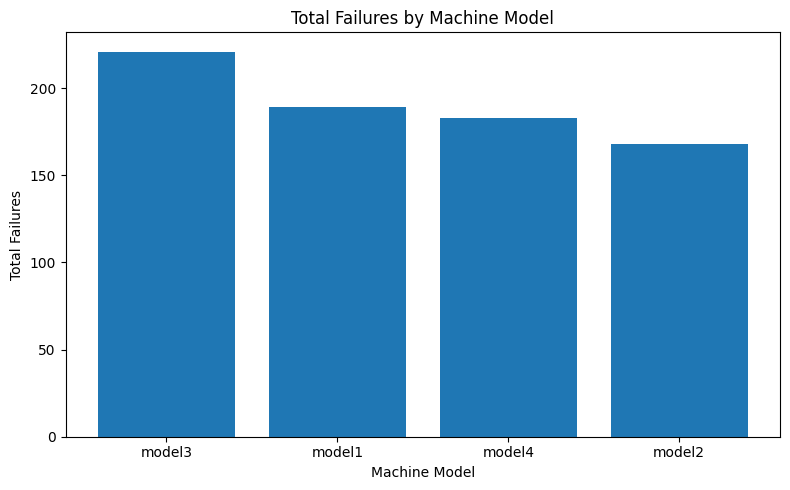

,total_failures
model,
model3,221
model1,189
model4,183
model2,168


In [6]:

failure_by_model = (
    reliability_features.groupby("model")["total_failures"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
plt.bar(
    failure_by_model.index.astype(str),
    failure_by_model.values
)
plt.title("Total Failures by Machine Model")
plt.xlabel("Machine Model")
plt.ylabel("Total Failures")
plt.tight_layout()
plt.show()

display(failure_by_model.rename("total_failures").to_frame())


Model 3 memiliki jumlah failure paling banyak secara keseluruhan, sedangkan Model 2 paling sedikit.
Namun, kita belum bisa menyimpulkan Model 3 paling tidak andal. Kita perlu membandingkan jumlah mesin pada setiap model karena model dengan lebih banyak mesin berpotensi memiliki lebih banyak event failure

##7.Rata-rata vibration: mesin dengan vs tanpa failure

Kita kelompokkan berdasarkan apakah mesin pernah tercatat mengalami failure selama periode dataset

Penting: ini analisis eksploratif, bukan model prediksi. Rata-rata vibration dihitung sepanjang periode observasi, sehingga kita belum bisa menyimpulkan apakah vibration meningkat sebelum failure terjadi.

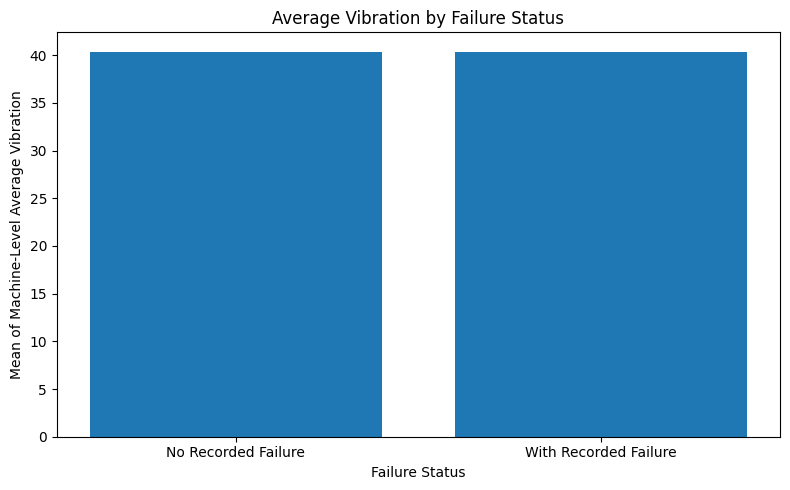

,avg_vibration
failure_status,
No Recorded Failure,40.322392
With Recorded Failure,40.386285


In [7]:

reliability_features["failure_status"] = np.where(
    reliability_features["total_failures"] > 0,
    "With Recorded Failure",
    "No Recorded Failure"
)

vibration_comparison = (
    reliability_features.groupby("failure_status")["avg_vibration"]
    .mean()
    .reindex(["No Recorded Failure", "With Recorded Failure"])
)

plt.figure(figsize=(8, 5))
plt.bar(
    vibration_comparison.index,
    vibration_comparison.values
)
plt.title("Average Vibration by Failure Status")
plt.ylabel("Mean of Machine-Level Average Vibration")
plt.xlabel("Failure Status")
plt.tight_layout()
plt.show()

display(vibration_comparison.to_frame("avg_vibration"))


Grafik menunjukkan rata-rata vibration kedua kelompok sangat mirip.
- No Recorded Failure: sekitar 40,32.
- With Recorded Failure: sekitar 39,97.
Interpretasi: Dalam agregasi rata-rata per mesin selama seluruh periode observasi, kelompok yang memiliki recorded failure justru menunjukkan rata-rata vibration sedikit lebih rendah.
Ini tidak membuktikan bahwa vibration rendah menyebabkan failure atau bahwa vibration tidak berguna untuk mendeteksi masalah. Rata-rata tahunan dapat menyembunyikan lonjakan vibration sesaat sebelum kerusakan. Analisis berdasarkan waktu sebelum failure akan lebih informatif.

##8.Tren vibration bulanan

Grafik ini memakai seluruh data telemetry yang diringkas per bulan agar lebih mudah dibaca

Perhatikan apakah rata-rata vibration relatif stabil atau menunjukkan tren tertentu. Tren bulanan bisa menyembunyikan lonjakan singkat, jadi jangan gunakan grafik ini sendirian untuk menentukan kondisi mesin.

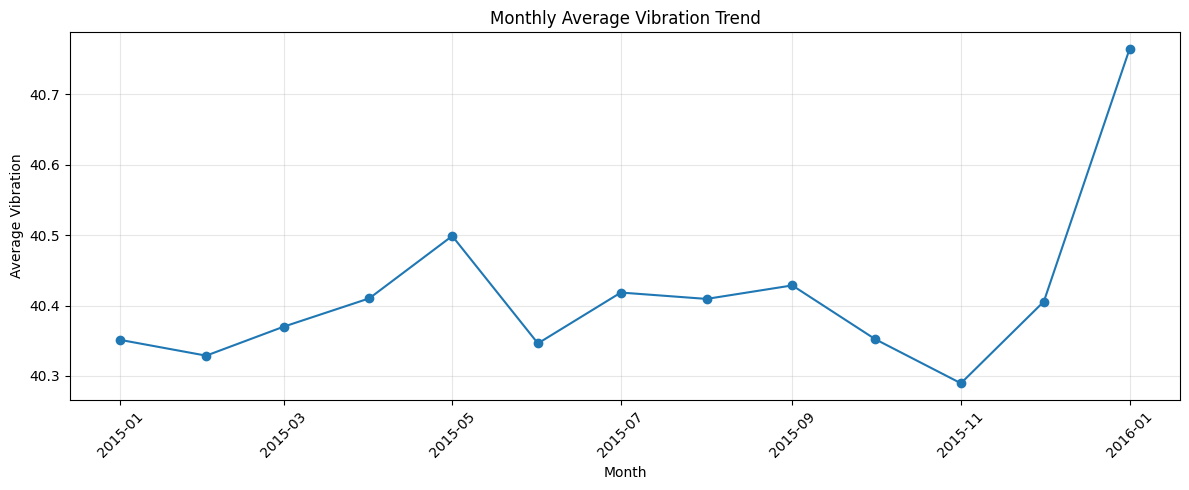

In [8]:

monthly_vibration = (
    telemetry.dropna(subset=["datetime", "vibration"])
    .assign(month=lambda df: df["datetime"].dt.to_period("M").dt.to_timestamp())
    .groupby("month")["vibration"]
    .mean()
)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_vibration.index,
    monthly_vibration.values,
    marker="o"
)
plt.title("Monthly Average Vibration Trend")
plt.xlabel("Month")
plt.ylabel("Average Vibration")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Dari grafik bulanan:
- Januari–Mei 2015: rata-rata vibration meningkat secara bertahap dari sekitar 40,35 menjadi 40,50.
- Juni–Oktober 2015: nilai berfluktuasi tetapi relatif stabil.
- November 2015: mencapai titik terendah, sekitar 40,28.
- Desember 2015–Januari 2016: meningkat, dengan titik terakhir sekitar 40,76.
Interpretasi: Rata-rata vibration bulanan secara umum relatif stabil, dengan kenaikan yang terlihat pada Januari 2016. Kenaikan terakhir ini layak diperiksa lebih lanjut, tetapi belum cukup untuk menyatakan kondisi mesin memburuk. Nilai terakhir juga berada pada Januari 2016, sehingga perlu diingat bahwa data mencakup periode hingga awal Januari 2016, bukan seluruh bulan Januari.

##9.Korelasi antar-sensor

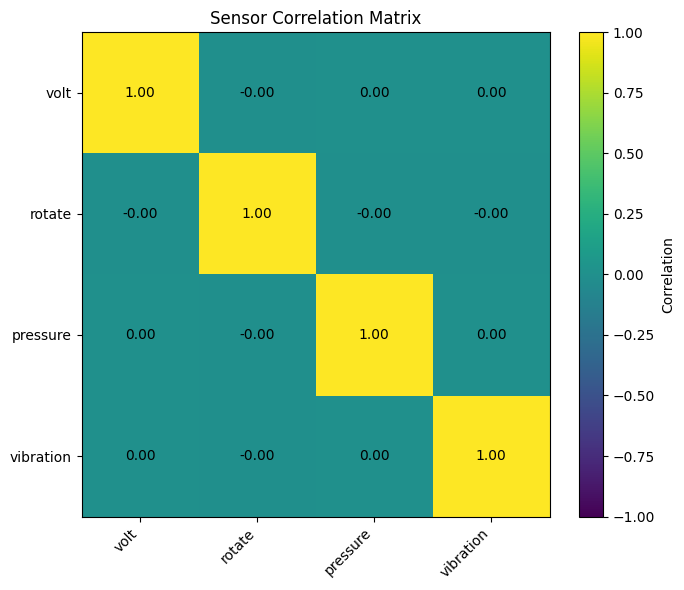

In [9]:

correlation = telemetry[sensor_cols].corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(correlation, vmin=-1, vmax=1, aspect="auto")

ax.set_xticks(range(len(sensor_cols)))
ax.set_yticks(range(len(sensor_cols)))
ax.set_xticklabels(sensor_cols, rotation=45, ha="right")
ax.set_yticklabels(sensor_cols)
ax.set_title("Sensor Correlation Matrix")

for i in range(len(sensor_cols)):
    for j in range(len(sensor_cols)):
        ax.text(
            j, i, f"{correlation.iloc[i, j]:.2f}",
            ha="center", va="center"
        )

fig.colorbar(im, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()


### Sensor Correlation Analysis

**Objective:** Examine the linear relationships among industrial sensor measurements.

**Findings:** The Pearson correlation matrix indicates that the pairwise linear correlations among voltage, rotation speed, pressure, and vibration are close to zero in the displayed results. Each sensor has a self-correlation of 1.00, as expected.

**Interpretation:** No strong pairwise linear relationship is apparent across the full telemetry dataset. However, weak overall correlation does not rule out nonlinear relationships, time-dependent patterns, or relationships that occur under specific operating conditions.

**Limitation:** Correlation alone cannot establish causality or determine whether a machine is approaching failure. Further analysis should investigate sensor trends over time and sensor behavior before recorded failure events.

Korelasi mendekati 1 berarti dua variabel cenderung bergerak searah secara linear; mendekati -1 berarti berlawanan arah; mendekati 0 berarti hubungan linear yang lemah. Korelasi tidak membuktikan sebab-akibat.

##10.Hubungan vibration dan pressure

Karena telemetry berisi ratusan ribu baris, kita gunakan sampel acak untuk membuat grafik lebih ringan ( scatter Plot )

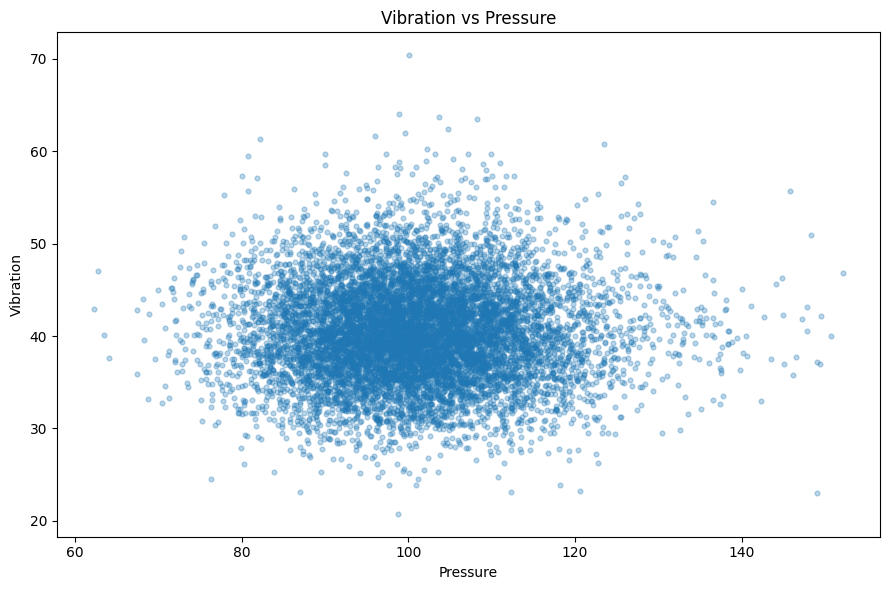

In [10]:

scatter_data = telemetry[
    ["pressure", "vibration"]
].dropna()

scatter_sample = scatter_data.sample(
    n=min(10000, len(scatter_data)),
    random_state=42
)

plt.figure(figsize=(9, 6))
plt.scatter(
    scatter_sample["pressure"],
    scatter_sample["vibration"],
    alpha=0.3,
    s=12
)
plt.title("Vibration vs Pressure")
plt.xlabel("Pressure")
plt.ylabel("Vibration")
plt.tight_layout()
plt.show()


Grafik ini membantu melihat pola hubungan sensor dan observasi ekstrem. Sampel acak dipakai hanya untuk visualisasi, bukan untuk mengubah dataset asli

Simpan grafik untuk portfolio

In [11]:
plt.savefig(
    PROJECT_DIR / "monthly_vibration_trend.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

##11.validasi hasil Feature Engineering

In [13]:

# Final validation of engineered features

print("=== FEATURE ENGINEERING VALIDATION ===")
print("Total rows:", len(reliability_features))
print("Unique machines:", reliability_features["machineID"].nunique())
print("Duplicate machine IDs:", reliability_features["machineID"].duplicated().sum())
print("Missing values:", reliability_features.isna().sum().sum())

print("\n=== FEATURE COLUMNS ===")
print(reliability_features.columns.tolist())

print("\n=== FAILURE STATUS ===")
print(reliability_features["failure_status"].value_counts())

# Validate the expected machine-level structure
assert len(reliability_features) == 100, "Expected 100 machines"
assert reliability_features["machineID"].nunique() == 100, "Machine IDs are not unique"
assert reliability_features["machineID"].duplicated().sum() == 0, "Duplicate machine IDs found"

# Save the final engineered dataset
output_file = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "machine_reliability_features.csv"
)

output_file.parent.mkdir(parents=True, exist_ok=True)
reliability_features.to_csv(output_file, index=False)

print("\nValidation passed.")
print("File saved to:", output_file)


=== FEATURE ENGINEERING VALIDATION ===
Total rows: 100
Unique machines: 100
Duplicate machine IDs: 0
Missing values: 0

=== FEATURE COLUMNS ===
['machineID', 'model', 'age', 'avg_volt', 'avg_rotate', 'avg_pressure', 'avg_vibration', 'max_vibration', 'std_vibration', 'telemetry_records', 'total_errors', 'total_failures', 'total_maintenance_events', 'failure_status']

=== FAILURE STATUS ===
failure_status
With Recorded Failure    98
No Recorded Failure       2
Name: count, dtype: int64

Validation passed.
File saved to: /content/drive/MyDrive/industrial-data-operations/data/processed/machine_reliability_features.csv


### Feature Engineering Validation — Interpretation

**Objective:** Verify the structural integrity and completeness of the machine-level feature dataset.

**Validation Results:**
- The dataset contains 100 rows representing 100 unique machines.
- No duplicate machine IDs were detected.
- No missing values were found in the final feature dataset.
- The validation assertions passed successfully.
- The engineered dataset was exported to `data/processed/machine_reliability_features.csv`.

**Failure Status Distribution:**
- 98 machines had at least one recorded failure.
- 2 machines had no recorded failure during the observation period.

**Conclusion:**
The machine-level feature dataset passed the implemented structural validation checks and is ready for further analysis. The dataset combines machine attributes, aggregated sensor measurements, and counts of recorded error, failure, and maintenance events.

**Limitation:** Passing these checks does not guarantee that every feature is semantically correct or suitable for predictive modeling. Failure status describes events observed across the dataset period; it must not be interpreted as a future failure prediction.

### Overall EDA Findings and Operational Recommendations

**Key Findings**

1. Machine 99 recorded the highest number of failure events among the top 10 machines displayed.
2. Model 3 recorded the highest total failure count among the machine models, although differences in the number of machines per model must be considered.
3. Average vibration was similar between machines with and without recorded failures when measured across the full observation period.
4. Monthly average vibration was relatively stable, with a noticeable increase in the final plotted month.
5. The scatter plot and correlation matrix did not reveal a strong overall linear relationship between pressure and vibration.

**Operational Recommendations**

- Investigate machines with high recorded failure counts using their historical failure and maintenance records.
- Compare failure rates across machine models, accounting for the number of machines in each model.
- Examine sensor readings in time windows before recorded failure events instead of relying only on full-period averages.
- Investigate unusual sensor trends and validate potential findings against operational records before making maintenance decisions.

**Conclusion**

The exploratory analysis identifies useful areas for further equipment reliability investigation. However, these findings are descriptive and do not establish causal relationships or provide validated failure predictions. Further time-based analysis is needed before developing a predictive maintenance model.